In [ ]:
!pip install xlrd pulp --quiet

In [ ]:
from google.colab import files

print("Загрузите три файла: Шихта.xls, Заказы.xls, Линии_дозирования.xls")
# uploaded = files.upload()

Загрузите три файла: Шихта.xls, Заказы.xls, Линии_дозирования.xls


In [ ]:
import time, random, math
import numpy as np
import pandas as pd
from collections import defaultdict, Counter
from scipy.optimize import milp, LinearConstraint, Bounds, linear_sum_assignment
from scipy.sparse import lil_matrix, csr_matrix

In [ ]:
random.seed(42)
np.random.seed(42)

In [ ]:
# ── Параметры модели (общие для всех методов) ─────────────────────
MONTH         = "март 2022"     # лист в Шихта.xls и Заказы.xls
LD_MONTH      = "март 2022"     # лист в Линии_дозирования.xls
SUPPLY_BUFFER = 1.30            # наличие = фактический расход × коэф.
MIN_DEMAND    = 0.0             # фильтр заказов (0 = все)

In [ ]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  ЯЧЕЙКА 4 — Подготовка данных                                  ║
# ╚══════════════════════════════════════════════════════════════════╝
print("\n[DATA] Загрузка таблиц...")
df_sh = pd.read_excel(f"Шихта.xls",             sheet_name=MONTH,    engine="xlrd")
df_z  = pd.read_excel(f"Заказы.xls",            sheet_name=MONTH,    engine="xlrd")
df_ld = pd.read_excel(f"Линии_дозирования.xls", sheet_name=LD_MONTH, engine="xlrd")

# Рецепты: {марка_массы_код: {номер_шихты: {компонент_код: норма_%}}}
recipes: dict[int, dict[int, dict[int, float]]] = {}
for _, row in df_sh.iterrows():
    mc = int(row["Марка массы, код"]); sn = int(row["Номер шихты"])
    cc = int(row["Компонент, код"]);   nm = float(row["Норма, %"])
    recipes.setdefault(mc, {}).setdefault(sn, {})[cc] = nm

# Заказы
orders: list[dict] = []
for idx, row in df_z.iterrows():
    mc = int(row["Марка массы, код"])
    if mc not in recipes: continue
    dem = float(row["Заказ, тн."])
    dop = float(row["Доп. заказ, тн."]) if pd.notna(row.get("Доп. заказ, тн.")) else 0.0
    if dem + dop < MIN_DEMAND: continue
    orders.append({"id": len(orders), "mass_code": mc,
                   "mass_name": str(row.get("Марка, наименование", "")),
                   "demand": dem + dop})

# Наличие компонентов: фактический расход × буфер.
# Компоненты с нулевым расходом исключаются из ограничений.
supply_raw = df_ld.groupby("Компонент, код")["Годное, тн."].sum()
supply: dict[int, float] = {
    int(c): float(v) * SUPPLY_BUFFER
    for c, v in supply_raw.items() if float(v) > 0
}
constrained_comps: list[int] = sorted(supply.keys())

# Показатель качества q_{m,r}: нормированный ранг шихты внутри марки ∈ (0,1]
quality: dict[tuple[int, int], float] = {}
for mc, sh in recipes.items():
    sn_s = sorted(sh.keys()); n = len(sn_s)
    for k, sn in enumerate(sn_s):
        quality[(mc, sn)] = (k + 1) / n

# Вспомогательные структуры
recipe_lists: dict[int, list[int]] = {mc: sorted(sh.keys()) for mc, sh in recipes.items()}
total_ton: float = sum(o["demand"] for o in orders)
mass_names: dict[int, str] = {
    int(r["Марка массы, код"]): str(r["Марка массы, наименование"])
    for _, r in df_sh.drop_duplicates("Марка массы, код").iterrows()
}

print(f"  Марок массы:          {len(recipes)}")
print(f"  Заказов:              {len(orders)}")
print(f"  Суммарный объём, тн.: {total_ton:.1f}")
print(f"  Компонентов (ограничение): {len(constrained_comps)}")


# ╔══════════════════════════════════════════════════════════════════╗
# ║  ЯЧЕЙКА 5 — Общие вспомогательные функции                      ║
# ╚══════════════════════════════════════════════════════════════════╝
def compute_metrics(asgn: list) -> tuple[float, float, dict]:
    """
    Вычислить для заданного назначения:
      obj_val  — значение целевой функции Σ q·d
      viol     — суммарное нарушение ресурсных ограничений, тн.
      used     — словарь {компонент: расход, тн.}
    """
    obj_val = 0.0
    used    = {c: 0.0 for c in supply}
    for i, sn in enumerate(asgn):
        if sn is None: continue
        mc = orders[i]["mass_code"]; d = orders[i]["demand"]
        obj_val += quality.get((mc, sn), 0) * d
        for c, nm in recipes[mc][sn].items():
            if c in used: used[c] += (nm / 100) * d
    viol = sum(max(0.0, used[c] - supply[c]) for c in supply)
    return obj_val, viol, used

def print_resources(used: dict, n: int = 12):
    """Вывести таблицу загрузки ресурсов (топ n по загрузке > 10%)."""
    binding = sorted(
        [(c, used.get(c, 0), supply[c], used.get(c, 0) / supply[c])
         for c in constrained_comps if used.get(c, 0) / supply[c] > 0.10],
        key=lambda r: -r[3]
    )
    print(f"  {'Компонент':>12}  {'Использовано':>12}  {'Наличие':>9}  {'Загрузка':>9}")
    print("  " + "-" * 48)
    for c, u, a, load in binding[:n]:
        flag = " ← НАРУШЕНИЕ" if u > a + 1e-6 else ""
        print(f"  {c:>12}  {u:>12.1f}  {a:>9.1f}  {load:>8.1%}{flag}")

def save_and_download(asgn: list, prefix: str, extra_dfs: dict = None):
    """Сохранить назначения в CSV и скачать."""
    rows = []
    for i, sn in enumerate(asgn):
        if sn is None: continue
        o = orders[i]; q = quality.get((o["mass_code"], sn), 0.0)
        rows.append({
            "Заказ_ID":         i,
            "Марка_массы_код":  o["mass_code"],
            "Марка_массы_наим": mass_names.get(o["mass_code"], ""),
            "Марка_наим":       o["mass_name"],
            "Шихта_номер":      sn,
            "Объём_тн":         round(o["demand"], 3),
            "Качество_q":       round(q, 4),
            "Вклад_q_d":        round(q * o["demand"], 3),
        })
    path = f"/content/{prefix}_results.csv"
    pd.DataFrame(rows).to_csv(path, index=False, encoding="utf-8-sig")
    files.download(path)

    if extra_dfs:
        for name, df in extra_dfs.items():
            p = f"/content/{prefix}_{name}.csv"
            df.to_csv(p, index=False, encoding="utf-8-sig")
            files.download(p)

    print(f"  Файлы скачаны: {prefix}_results.csv" +
          (f", {', '.join(prefix+'_'+k+'.csv' for k in (extra_dfs or {}))}") if extra_dfs else "")

print("\nДанные готовы. Запускайте ячейки нужного метода.")
print("Доступные переменные: orders, recipes, supply, quality,")
print("  constrained_comps, recipe_lists, total_ton, mass_names")
print("Доступные функции:    compute_metrics(), print_resources(), save_and_download()")


[DATA] Загрузка таблиц...
  Марок массы:          23
  Заказов:              222
  Суммарный объём, тн.: 7357.2
  Компонентов (ограничение): 46

Данные готовы. Запускайте ячейки нужного метода.
Доступные переменные: orders, recipes, supply, quality,
  constrained_comps, recipe_lists, total_ton, mass_names
Доступные функции:    compute_metrics(), print_resources(), save_and_download()


In [ ]:
# Точный ILP: солвер HiGHS
# Гарантирует оптимальное допустимое решение.

print("=" * 60)
print("МЕТОД: MILP_HiGHS")
print("=" * 60)

# Переменные x_{o,r}: (order_id, mass_code, shikhta_num)
var_list = [(o["id"], o["mass_code"], sn)
            for o in orders for sn in recipes[o["mass_code"]]]
var_index = {v: i for i, v in enumerate(var_list)}
nv = len(var_list)

c_obj = np.array([-quality.get((mc, sn), 0.5) * orders[oid]["demand"]
                   for oid, mc, sn in var_list])

# Матрица ограничений C1 (= 1) и C2 (<= supply)
comp_to_row = {c: len(orders) + i for i, c in enumerate(constrained_comps)}
nc = len(orders) + len(constrained_comps)
A  = lil_matrix((nc, nv))
bl = np.full(nc, -np.inf); bh = np.full(nc, np.inf)

for o in orders:
    r = o["id"]; bl[r] = bh[r] = 1.0
    for sn in recipes[o["mass_code"]]:
        key = (o["id"], o["mass_code"], sn)
        if key in var_index: A[r, var_index[key]] = 1.0

for i, (oid, mc, sn) in enumerate(var_list):
    d = orders[oid]["demand"]
    for c, nm in recipes[mc][sn].items():
        if c in comp_to_row: A[comp_to_row[c], i] += (nm / 100) * d

for c in constrained_comps:
    bh[comp_to_row[c]] = supply[c]

A_csr = csr_matrix(A)
print(f"  Переменных: {nv}, ограничений: {nc}, nnz: {A_csr.nnz}")

t0 = time.time()
result = milp(c_obj,
              constraints=LinearConstraint(A_csr, bl, bh),
              integrality=np.ones(nv),
              bounds=Bounds(np.zeros(nv), np.ones(nv)),
              options={"disp": False, "time_limit": 300})
elapsed = time.time() - t0

asgn = [None] * len(orders)
if result.x is not None:
    for i, (oid, mc, sn) in enumerate(var_list):
        if result.x[i] > 0.5: asgn[oid] = sn

obj_val, viol, used = compute_metrics(asgn)
print(f"  Статус:  {result.message}")
print(f"  Время:   {elapsed:.2f} с")
print(f"  ЦФ:      {obj_val:.2f}")
print(f"  Нарушение: {viol:.4f} тн.  ({'Допустимо' if viol < 1e-3 else 'НАРУШЕНИЕ'})")
print_resources(used)
save_and_download(asgn, "milp_highs")

МЕТОД: MILP_HiGHS
  Переменных: 33847, ограничений: 268, nnz: 258813
  Статус:  Optimization terminated successfully. (HiGHS Status 7: Optimal)
  Время:   47.45 с
  ЦФ:      5511.37
  Нарушение: 0.0000 тн.  (Допустимо)
     Компонент  Использовано    Наличие   Загрузка
  ------------------------------------------------
         72702         835.5      835.5    100.0%
         72881          23.9       23.9    100.0%
         99126           3.8        3.8    100.0%
        101217          18.4       18.4    100.0%
        110585           2.8        2.8     99.0%
         62345           2.1        2.1     98.7%
         33890           0.4        0.4     95.6%
         72899           0.0        0.0     93.4%
         93521           0.0        0.0     92.4%
         65286           0.5        0.5     89.5%
         62346           2.6        3.0     87.5%
         72557           2.0        2.5     82.5%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# LP-релаксация: переменные непрерывны ∈ [0,1].
# Даёт верхнюю оценку (UB) оптимума ILP.
# После решения LP — жадное округление: argmax x_{o,r}.

print("=" * 60)
print("МЕТОД: LP_Relax")
print("=" * 60)

var_list = [(o["id"], o["mass_code"], sn)
            for o in orders for sn in recipes[o["mass_code"]]]
var_index = {v: i for i, v in enumerate(var_list)}
nv = len(var_list)

c_obj = np.array([-quality.get((mc, sn), 0.5) * orders[oid]["demand"]
                   for oid, mc, sn in var_list])

comp_to_row = {c: len(orders) + i for i, c in enumerate(constrained_comps)}
nc = len(orders) + len(constrained_comps)
A  = lil_matrix((nc, nv))
bl = np.full(nc, -np.inf); bh = np.full(nc, np.inf)

for o in orders:
    r = o["id"]; bl[r] = bh[r] = 1.0
    for sn in recipes[o["mass_code"]]:
        key = (o["id"], o["mass_code"], sn)
        if key in var_index: A[r, var_index[key]] = 1.0

for i, (oid, mc, sn) in enumerate(var_list):
    d = orders[oid]["demand"]
    for c, nm in recipes[mc][sn].items():
        if c in comp_to_row: A[comp_to_row[c], i] += (nm / 100) * d

for c in constrained_comps:
    bh[comp_to_row[c]] = supply[c]

A_csr = csr_matrix(A)

t0 = time.time()
result = milp(c_obj,
              constraints=LinearConstraint(A_csr, bl, bh),
              integrality=np.zeros(nv),        # ← LP, не ILP
              bounds=Bounds(np.zeros(nv), np.ones(nv)),
              options={"disp": False})
elapsed = time.time() - t0

lp_ub = -result.fun if result.x is not None else float("nan")

# Жадное округление
asgn = [None] * len(orders)
if result.x is not None:
    xv = result.x
    for o in orders:
        mc = o["mass_code"]
        best_val, best_sn = -1.0, None
        for sn in recipes[mc]:
            key = (o["id"], mc, sn)
            if key in var_index:
                v = xv[var_index[key]]
                if v > best_val: best_val, best_sn = v, sn
        asgn[o["id"]] = best_sn

obj_val, viol, used = compute_metrics(asgn)
print(f"  Время LP:   {elapsed:.3f} с")
print(f"  LP UB:      {lp_ub:.3f}")
print(f"  ЦФ (после округления): {obj_val:.2f}")
print(f"  MIP Gap:    {100*(lp_ub - obj_val)/lp_ub:.4f}%")
print(f"  Нарушение:  {viol:.4f} тн.  ({'Допустимо' if viol < 1e-3 else 'НАРУШЕНИЕ'})")
print_resources(used)
save_and_download(asgn, "lp_relax")

МЕТОД: LP_Relax
  Время LP:   1.836 с
  LP UB:      5511.931
  ЦФ (после округления): 5497.01
  MIP Gap:    0.2706%
  Нарушение:  2.5778 тн.  (НАРУШЕНИЕ)
     Компонент  Использовано    Наличие   Загрузка
  ------------------------------------------------
        110585           3.8        2.8    136.2% ← НАРУШЕНИЕ
         62345           2.5        2.1    117.3% ← НАРУШЕНИЕ
         62346           3.3        3.0    109.7% ← НАРУШЕНИЕ
         72881          24.8       23.9    103.8% ← НАРУШЕНИЕ
        101217          18.4       18.4     99.8%
         72702         831.5      835.5     99.5%
         72899           0.0        0.0     93.4%
         99126           3.6        3.8     92.6%
         72557           2.1        2.5     86.6%
         93521           0.0        0.0     74.4%
         72630          45.1       62.9     71.6%
         72833          25.2       44.7     56.5%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# # Точный ILP через PuLP + CBC (COIN-OR Branch and Cut)

# import pulp

# print("=" * 60)
# print("МЕТОД: ILP_CBC")
# print("=" * 60)

# var_list = [(o["id"], o["mass_code"], sn)
#             for o in orders for sn in recipes[o["mass_code"]]]
# x = {(oid, mc, sn): pulp.LpVariable(f"x_{oid}_{mc}_{sn}", cat="Binary")
#      for oid, mc, sn in var_list}

# prob = pulp.LpProblem("shihta_cbc", pulp.LpMaximize)
# prob += pulp.lpSum(quality.get((mc, sn), 0.5) * orders[oid]["demand"] * x[(oid, mc, sn)]
#                    for oid, mc, sn in var_list)
# for o in orders:
#     mc = o["mass_code"]
#     prob += (pulp.lpSum(x[(o["id"], mc, sn)] for sn in recipes[mc]) == 1)
# for c in constrained_comps:
#     prob += (pulp.lpSum(
#         (recipes[mc][sn].get(c, 0) / 100) * orders[oid]["demand"] * x[(oid, mc, sn)]
#         for oid, mc, sn in var_list if c in recipes[mc][sn]
#     ) <= supply[c])

# print(f"  Переменных: {len(x)}, C1: {len(orders)}, C2: {len(constrained_comps)}")

# t0 = time.time()
# prob.solve(pulp.PULP_CBC_CMD(msg=1, timeLimit=300))
# elapsed = time.time() - t0

# asgn = [None] * len(orders)
# for oid, mc, sn in var_list:
#     v = pulp.value(x[(oid, mc, sn)])
#     if v is not None and v > 0.5: asgn[oid] = sn

# obj_val, viol, used = compute_metrics(asgn)
# print(f"  Статус:    {pulp.LpStatus[prob.status]}")
# print(f"  Время:     {elapsed:.2f} с")
# print(f"  ЦФ:        {obj_val:.2f}")
# print(f"  Нарушение: {viol:.4f} тн.  ({'Допустимо' if viol < 1e-3 else 'НАРУШЕНИЕ'})")
# print_resources(used)
# save_and_download(asgn, "ilp_cbc")

In [ ]:
# Жадный алгоритм: заказы обрабатываются в порядке убывания
# максимального качества доступного рецепта.

print("=" * 60)
print("МЕТОД: Greedy_Quality")
print("=" * 60)

def greedy(order_indices):
    asgn = [None] * len(orders)
    comp_used = {c: 0.0 for c in supply}
    fallback  = 0
    for oi in order_indices:
        o  = orders[oi]; mc = o["mass_code"]; d = o["demand"]
        sorted_sn = sorted(recipe_lists[mc], key=lambda sn: -quality.get((mc, sn), 0))
        chosen = None
        for sn in sorted_sn:
            if all(comp_used.get(c, 0) + (nm / 100) * d <= supply[c]
                   for c, nm in recipes[mc][sn].items() if c in supply):
                chosen = sn; break
        if chosen is None:
            chosen = sorted_sn[0]; fallback += 1
        asgn[oi] = chosen
        for c, nm in recipes[mc][chosen].items():
            if c in supply: comp_used[c] = comp_used.get(c, 0) + (nm / 100) * d
    return asgn, fallback

order_by_quality = sorted(range(len(orders)),
    key=lambda i: -max(quality.get((orders[i]["mass_code"], sn), 0)
                       for sn in recipe_lists[orders[i]["mass_code"]]))

t0 = time.time()
asgn, fallback = greedy(order_by_quality)
elapsed = time.time() - t0

obj_val, viol, used = compute_metrics(asgn)
print(f"  Время:     {elapsed:.4f} с")
print(f"  ЦФ:        {obj_val:.2f}")
print(f"  Нарушение: {viol:.4f} тн.  ({'Допустимо' if viol < 1e-3 else 'НАРУШЕНИЕ'})")
print(f"  Fallback:  {fallback} заказов (рецепт выбран с нарушением ресурсов)")
print_resources(used)
save_and_download(asgn, "greedy_quality")

МЕТОД: Greedy_Quality
  Время:     0.0284 с
  ЦФ:        5418.23
  Нарушение: 9.7528 тн.  (НАРУШЕНИЕ)
  Fallback:  4 заказов (рецепт выбран с нарушением ресурсов)
     Компонент  Использовано    Наличие   Загрузка
  ------------------------------------------------
        101217          24.3       18.4    131.6% ← НАРУШЕНИЕ
         72881          27.8       23.9    116.2% ← НАРУШЕНИЕ
         99126           3.9        3.8    101.3% ← НАРУШЕНИЕ
         62345           2.1        2.1     99.7%
         33890           0.4        0.4     98.9%
        110585           2.7        2.8     96.8%
         72702         780.4      835.5     93.4%
         72899           0.0        0.0     93.4%
         65286           0.5        0.5     90.8%
         62346           2.7        3.0     90.3%
         72630          52.6       62.9     83.5%
         72557           1.9        2.5     77.1%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Жадный алгоритм: заказы обрабатываются в порядке убывания тоннажа.

print("=" * 60)
print("МЕТОД: Greedy_Demand")
print("=" * 60)

def greedy(order_indices):
    asgn = [None] * len(orders)
    comp_used = {c: 0.0 for c in supply}
    fallback  = 0
    for oi in order_indices:
        o  = orders[oi]; mc = o["mass_code"]; d = o["demand"]
        sorted_sn = sorted(recipe_lists[mc], key=lambda sn: -quality.get((mc, sn), 0))
        chosen = None
        for sn in sorted_sn:
            if all(comp_used.get(c, 0) + (nm / 100) * d <= supply[c]
                   for c, nm in recipes[mc][sn].items() if c in supply):
                chosen = sn; break
        if chosen is None:
            chosen = sorted_sn[0]; fallback += 1
        asgn[oi] = chosen
        for c, nm in recipes[mc][chosen].items():
            if c in supply: comp_used[c] = comp_used.get(c, 0) + (nm / 100) * d
    return asgn, fallback

order_by_demand = sorted(range(len(orders)), key=lambda i: -orders[i]["demand"])

t0 = time.time()
asgn, fallback = greedy(order_by_demand)
elapsed = time.time() - t0

obj_val, viol, used = compute_metrics(asgn)
print(f"  Время:     {elapsed:.4f} с")
print(f"  ЦФ:        {obj_val:.2f}")
print(f"  Нарушение: {viol:.4f} тн.  ({'Допустимо' if viol < 1e-3 else 'НАРУШЕНИЕ'})")
print(f"  Fallback:  {fallback} заказов")
print_resources(used)
save_and_download(asgn, "greedy_demand")

МЕТОД: Greedy_Demand
  Время:     0.0732 с
  ЦФ:        5712.58
  Нарушение: 145.1815 тн.  (НАРУШЕНИЕ)
  Fallback:  96 заказов
     Компонент  Использовано    Наличие   Загрузка
  ------------------------------------------------
        110585          52.7        2.8   1886.4% ← НАРУШЕНИЕ
         62346          35.8        3.0   1191.7% ← НАРУШЕНИЕ
         62345          19.5        2.1    918.4% ← НАРУШЕНИЕ
         99126           7.4        3.8    191.1% ← НАРУШЕНИЕ
         72702         876.9      835.5    105.0% ← НАРУШЕНИЕ
        101217          18.5       18.4    100.4% ← НАРУШЕНИЕ
         72881          24.0       23.9    100.3% ← НАРУШЕНИЕ
         72557           2.4        2.5     99.0%
         33890           0.4        0.4     97.6%
         72899           0.0        0.0     93.4%
         72630          37.5       62.9     59.7%
         72833          25.1       44.7     56.2%


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Имитация отжига. Параметры меняйте здесь:
SA_ITERS = 200_000
T_START  = 500.0
T_END    = 0.01
PENALTY  = 5000.0     # штраф за 1 тн. нарушения ресурсов
ALPHA    = (T_END / T_START) ** (1.0 / SA_ITERS)

print("=" * 60)
print("МЕТОД: SimAnneal")
print(f"  Итераций={SA_ITERS}, T={T_START}→{T_END}, α={ALPHA:.8f}")
print("=" * 60)

def sa_energy(asgn, used):
    obj  = sum(quality.get((orders[i]["mass_code"], sn), 0) * orders[i]["demand"]
               for i, sn in enumerate(asgn))
    viol = sum(max(0.0, used[c] - supply[c]) for c in supply)
    return -obj + PENALTY * viol

def delta_used(i, old_sn, new_sn):
    mc = orders[i]["mass_code"]; d = orders[i]["demand"]
    delta = {}
    for c in set(list(recipes[mc][old_sn]) + list(recipes[mc][new_sn])):
        if c in supply:
            dv = (recipes[mc][new_sn].get(c, 0) - recipes[mc][old_sn].get(c, 0)) / 100 * d
            if dv: delta[c] = dv
    return delta

# Стартовое решение: лучший рецепт по качеству для каждого заказа
cur_asgn = [max(recipe_lists[o["mass_code"]], key=lambda sn: quality.get((o["mass_code"], sn), 0))
            for o in orders]
_, _, cur_used = compute_metrics(cur_asgn)
cur_e = sa_energy(cur_asgn, cur_used)
best_asgn = list(cur_asgn); best_e = cur_e; best_used = dict(cur_used)

T = T_START; history = []
t0 = time.time()

for it in range(SA_ITERS):
    idx    = random.randrange(len(orders))
    mc     = orders[idx]["mass_code"]
    old_sn = cur_asgn[idx]
    new_sn = random.choice(recipe_lists[mc])
    if new_sn == old_sn: T *= ALPHA; continue

    delta = delta_used(idx, old_sn, new_sn)
    new_used = dict(cur_used)
    for c, dv in delta.items(): new_used[c] += dv
    new_asgn = list(cur_asgn); new_asgn[idx] = new_sn
    new_e = sa_energy(new_asgn, new_used)

    if new_e < cur_e or random.random() < math.exp(-(new_e - cur_e) / T):
        cur_asgn, cur_used, cur_e = new_asgn, new_used, new_e
        if cur_e < best_e:
            best_asgn, best_e, best_used = list(cur_asgn), cur_e, dict(cur_used)

    T *= ALPHA
    if (it + 1) % (SA_ITERS // 10) == 0:
        viol = sum(max(0, best_used[c] - supply[c]) for c in supply)
        obj  = sum(quality.get((orders[i]["mass_code"], sn), 0) * orders[i]["demand"]
                   for i, sn in enumerate(best_asgn))
        history.append({"iter": it+1, "T": round(T, 6),
                        "ЦФ_best": round(obj, 2), "нарушение": round(viol, 3)})
        print(f"  iter {it+1:>6}  T={T:.4f}  ЦФ={obj:.2f}  нарушение={viol:.3f}")

elapsed = time.time() - t0
obj_val, viol, used = compute_metrics(best_asgn)
print(f"\n  Время: {elapsed:.2f} с | ЦФ: {obj_val:.2f} | Нарушение: {viol:.4f} тн.")
print(f"  {'Допустимо' if viol < 1e-3 else 'НАРУШЕНИЕ'}")
print_resources(used)
save_and_download(best_asgn, "sim_anneal",
                  extra_dfs={"convergence": pd.DataFrame(history)})

МЕТОД: SimAnneal
  Итераций=200000, T=500.0→0.01, α=0.99994590
  iter  20000  T=169.4623  ЦФ=3765.58  нарушение=0.000
  iter  40000  T=57.4349  ЦФ=3813.69  нарушение=0.000
  iter  60000  T=19.4661  ЦФ=4344.76  нарушение=0.000
  iter  80000  T=6.5975  ЦФ=4602.97  нарушение=0.000
  iter 100000  T=2.2361  ЦФ=5007.79  нарушение=0.000
  iter 120000  T=0.7579  ЦФ=5189.18  нарушение=0.000
  iter 140000  T=0.2569  ЦФ=5277.70  нарушение=0.000
  iter 160000  T=0.0871  ЦФ=5309.63  нарушение=0.000
  iter 180000  T=0.0295  ЦФ=5331.53  нарушение=0.000
  iter 200000  T=0.0100  ЦФ=5332.98  нарушение=0.000

  Время: 42.98 с | ЦФ: 5332.98 | Нарушение: 0.0000 тн.
  Допустимо
     Компонент  Использовано    Наличие   Загрузка
  ------------------------------------------------
         99126           3.8        3.8    100.0%
         72702         835.0      835.5    100.0%
        101217          18.4       18.4     99.9%
         72881          23.8       23.9     99.6%
        110585           2.8     

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

  Файлы скачаны: sim_anneal_results.csv, sim_anneal_convergence.csv


  MILP_HiGHS            ЦФ= 5511.37  нарушение=   0.000  OK
  LP_Relax              ЦФ= 5497.01  нарушение=   2.578  НАРУШЕНИЕ
  ПРОПУСК ILP_CBC: файл не найден (/content/ilp_cbc_results.csv)
  Greedy_Quality        ЦФ= 5418.23  нарушение=   9.753  НАРУШЕНИЕ
  Greedy_Demand         ЦФ= 5712.58  нарушение= 145.182  НАРУШЕНИЕ
  SimAnneal             ЦФ= 5332.98  нарушение=   0.000  OK
  ПРОПУСК Random_Restart: файл не найден (/content/random_restart_results.csv)
  ПРОПУСК Decomp_Hungarian: файл не найден (/content/hungarian_results.csv)

═════════════════════════════════════════════════════════════════════════════════════
         Метод      ЦФ  Время, с  Нарушение, тн.  Допустимо  Gap к лучшему, %
    MILP_HiGHS 5511.37     9.700           0.000       True             0.000
      LP_Relax 5497.01     0.940           2.578      False             0.261
Greedy_Quality 5418.23     0.017           9.753      False             1.690
 Greedy_Demand 5712.58     0.033         145.182      False 

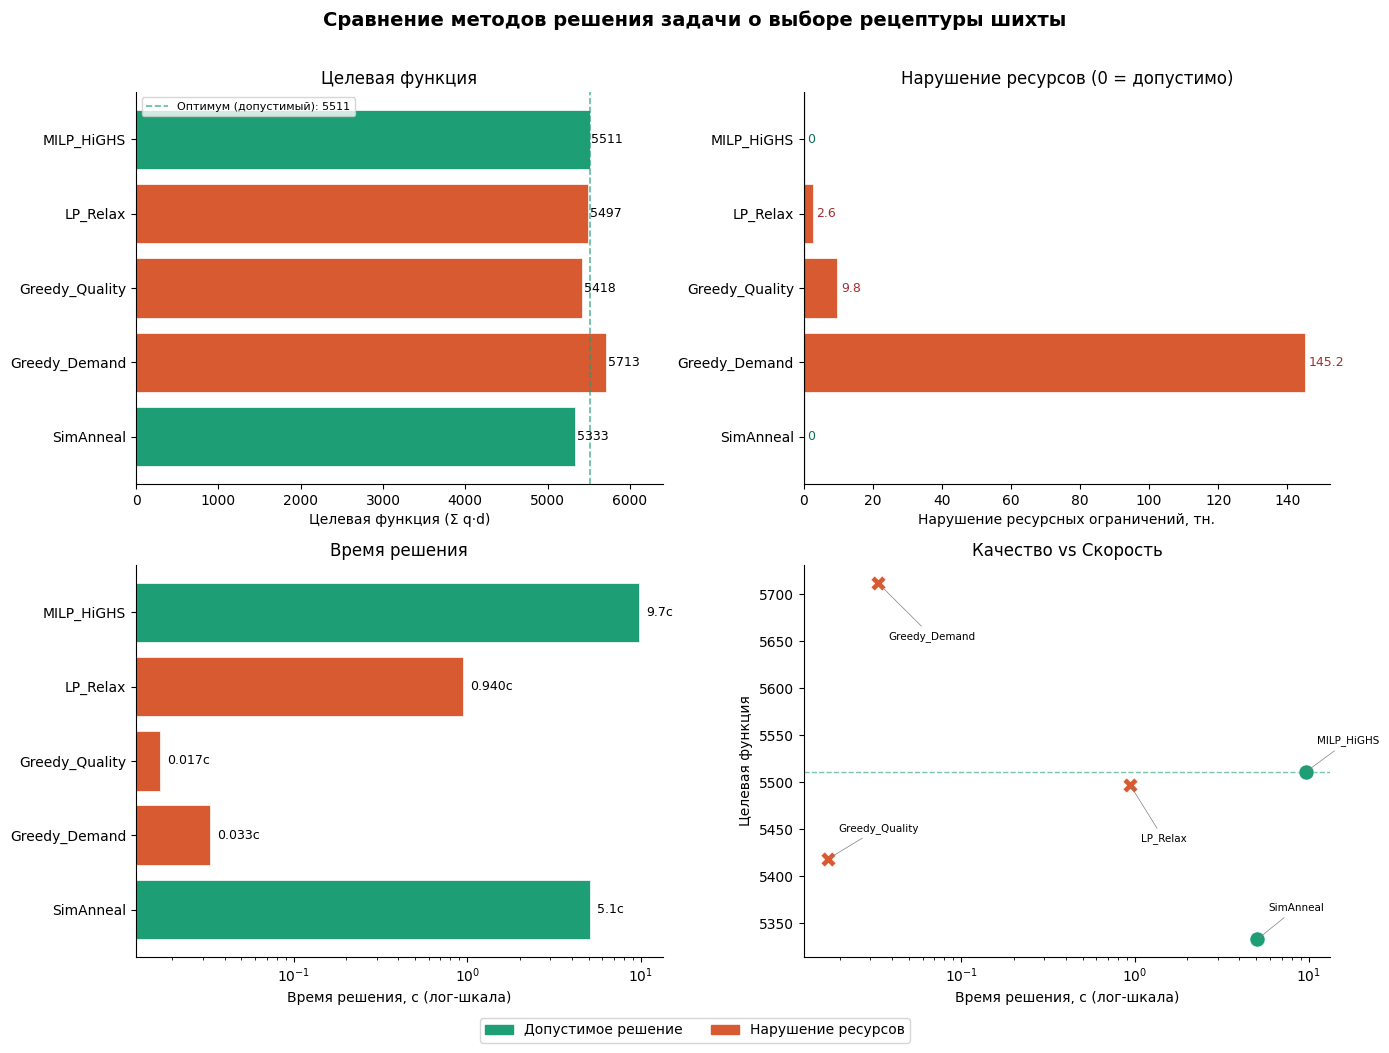

График сохранён: comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Готово.


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
import os

# Берутся из выводов выше
TIMES = {
    "MILP_HiGHS":      9.70,
    "LP_Relax":        0.94,
    "ILP_CBC":       183.33,
    "Greedy_Quality":  0.017,
    "Greedy_Demand":   0.033,
    "SimAnneal":       5.08,
    "Random_Restart":  0.28,
    "Decomp_Hungarian":0.006,
}

# ── Файлы результатов и их названия ───────────────────────────────
METHOD_FILES = {
    "MILP_HiGHS":       "/content/milp_highs_results.csv",
    "LP_Relax":         "/content/lp_relax_results.csv",
    "ILP_CBC":          "/content/ilp_cbc_results.csv",
    "Greedy_Quality":   "/content/greedy_quality_results.csv",
    "Greedy_Demand":    "/content/greedy_demand_results.csv",
    "SimAnneal":        "/content/sim_anneal_results.csv",
    "Random_Restart":   "/content/random_restart_results.csv",
    "Decomp_Hungarian": "/content/hungarian_results.csv",
}

# ── Восстановление назначений и пересчёт метрик ───────────────────
def load_assignment(path):
    """Читает CSV и строит список назначений asgn[order_id] = shikhta_num."""
    if not os.path.exists(path):
        return None
    df = pd.read_csv(path)
    asgn = [None] * len(orders)
    for _, row in df.iterrows():
        oid = int(row["Заказ_ID"])
        sn  = int(row["Шихта_номер"])
        if oid < len(orders):
            asgn[oid] = sn
    return asgn

rows = []
assignments_all = {}

for name, path in METHOD_FILES.items():
    asgn = load_assignment(path)
    if asgn is None:
        print(f"  ПРОПУСК {name}: файл не найден ({path})")
        continue
    obj_val, viol, used = compute_metrics(asgn)
    filled  = sum(1 for s in asgn if s is not None)
    tons    = sum(orders[i]["demand"] for i, s in enumerate(asgn) if s is not None)
    assignments_all[name] = asgn
    rows.append({
        "Метод":           name,
        "ЦФ":              round(obj_val, 2),
        "Время, с":        TIMES.get(name, 0),
        "Заказов":         filled,
        "Объём, тн.":      round(tons, 1),
        "Нарушение, тн.":  round(viol, 3),
        "Допустимо":       viol < 1e-3,
    })
    print(f"  {name:<20}  ЦФ={obj_val:>8.2f}  "
          f"нарушение={viol:>8.3f}  {'OK' if viol < 1e-3 else 'НАРУШЕНИЕ'}")

df = pd.DataFrame(rows)
best_obj = df.loc[df["Допустимо"], "ЦФ"].max()
df["Gap к лучшему, %"] = ((best_obj - df["ЦФ"]) / best_obj * 100).round(3)

# ── Итоговая таблица ──────────────────────────────────────────────
print("\n" + "═" * 85)
print(df[["Метод","ЦФ","Время, с","Нарушение, тн.","Допустимо","Gap к лучшему, %"]].to_string(index=False))
print("═" * 85)

# ═══════════════════════════════════════════════════════════════════
# ГРАФИКИ
# ═══════════════════════════════════════════════════════════════════
METHODS   = df["Метод"].tolist()
CF        = df["ЦФ"].tolist()
VIOL      = df["Нарушение, тн."].tolist()
TIMES_V   = df["Время, с"].tolist()
FEASIBLE  = df["Допустимо"].tolist()
COLORS    = ["#1D9E75" if f else "#D85A30" for f in FEASIBLE]

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Сравнение методов решения задачи о выборе рецептуры шихты",
             fontsize=14, fontweight="bold", y=1.01)

# ── График 1: Целевая функция ──────────────────────────────────────
ax = axes[0, 0]
bars = ax.barh(METHODS, CF, color=COLORS, edgecolor="white", linewidth=0.5)
ax.axvline(x=best_obj, color="#1D9E75", linestyle="--", linewidth=1.2, alpha=0.7,
           label=f"Оптимум (допустимый): {best_obj:.0f}")
for bar, v in zip(bars, CF):
    ax.text(bar.get_width() + 20, bar.get_y() + bar.get_height()/2,
            f"{v:.0f}", va="center", fontsize=9)
ax.set_xlabel("Целевая функция (Σ q·d)")
ax.set_title("Целевая функция")
ax.legend(fontsize=8)
ax.set_xlim(0, max(CF) * 1.12)
ax.invert_yaxis()
ax.spines[["top","right"]].set_visible(False)

# ── График 2: Нарушение ресурсов ──────────────────────────────────
ax = axes[0, 1]
bars = ax.barh(METHODS, VIOL, color=COLORS, edgecolor="white", linewidth=0.5)
ax.axvline(x=0, color="black", linewidth=0.8)
for bar, v in zip(bars, VIOL):
    if v > 0:
        ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
                f"{v:.1f}", va="center", fontsize=9, color="#A32D2D")
    else:
        ax.text(1, bar.get_y() + bar.get_height()/2,
                "0", va="center", fontsize=9, color="#0F6E56")
ax.set_xlabel("Нарушение ресурсных ограничений, тн.")
ax.set_title("Нарушение ресурсов (0 = допустимо)")
ax.invert_yaxis()
ax.spines[["top","right"]].set_visible(False)

# ── График 3: Время решения (лог-шкала) ───────────────────────────
ax = axes[1, 0]
bars = ax.barh(METHODS, TIMES_V, color=COLORS, edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
for bar, v in zip(bars, TIMES_V):
    label = f"{v:.3f}с" if v < 1 else f"{v:.1f}с"
    ax.text(bar.get_width() * 1.1, bar.get_y() + bar.get_height()/2,
            label, va="center", fontsize=9)
ax.set_xlabel("Время решения, с (лог-шкала)")
ax.set_title("Время решения")
ax.invert_yaxis()
ax.spines[["top","right"]].set_visible(False)

# ── График 4: ЦФ vs Время (scatter) ──────────────────────────────
ax = axes[1, 1]
for i, (name, cf, t, feas) in enumerate(zip(METHODS, CF, TIMES_V, FEASIBLE)):
    color  = "#1D9E75" if feas else "#D85A30"
    marker = "o" if feas else "X"
    ax.scatter(t, cf, c=color, s=120, marker=marker, zorder=3, edgecolors="white", linewidths=0.5)
    offset_x = t * 0.15
    offset_y = 30 if i % 2 == 0 else -60
    ax.annotate(name, (t, cf), xytext=(t + offset_x, cf + offset_y),
                fontsize=7.5, ha="left",
                arrowprops=dict(arrowstyle="-", color="gray", lw=0.5))

ax.set_xscale("log")
ax.set_xlabel("Время решения, с (лог-шкала)")
ax.set_ylabel("Целевая функция")
ax.set_title("Качество vs Скорость")
ax.axhline(y=best_obj, color="#1D9E75", linestyle="--", linewidth=1, alpha=0.6)
ax.spines[["top","right"]].set_visible(False)

patch_ok  = mpatches.Patch(color="#1D9E75", label="Допустимое решение")
patch_no  = mpatches.Patch(color="#D85A30", label="Нарушение ресурсов")
fig.legend(handles=[patch_ok, patch_no], loc="lower center",
           ncol=2, fontsize=10, bbox_to_anchor=(0.5, -0.03))

plt.tight_layout()
plt.savefig("/content/comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("График сохранён: comparison.png")

# ── Экспорт сводной таблицы ───────────────────────────────────────
df.to_csv("/content/comparison_summary.csv", index=False, encoding="utf-8-sig")
files.download("/content/comparison.png")
files.download("/content/comparison_summary.csv")
print("Готово.")

[1] Загрузка данных для вычисления q...
  Загружено.
  q2_press_yield: данных по 64 шихтам, fallback для 624 шихт
  q3_conformity:  данных по 93 шихтам, fallback для 593 шихт
  q4_group:       покрыто 635 шихт через группы изделий
  q5_composite:   W2=0.4, W3=0.4, W4=0.2

  Всего шихт: 686
       Марка_массы_код  Шихта_номер  q1_rank  q2_press_yield  q3_conformity  q4_group  q5_composite
count          686.000      686.000  686.000         686.000        686.000   686.000       686.000
mean        143160.060       84.378    0.517           0.549          0.548     0.717         0.582
std          31108.484       87.398    0.292           0.302          0.309     0.095         0.237
min          44119.000        1.000    0.005           0.000          0.000     0.000         0.067
25%         153355.000       30.000    0.268           0.292          0.279     0.725         0.381
50%         153356.000       73.000    0.512           0.555          0.547     0.725         0.587
75%      

/tmp/ipykernel_2724/894737872.py:333: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(q_names, rotation=30, ha="right", fontsize=9)
/tmp/ipykernel_2724/894737872.py:344: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(q_names, rotation=30, ha="right", fontsize=9)
/tmp/ipykernel_2724/894737872.py:357: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(q_names, rotation=30, ha="right", fontsize=9)


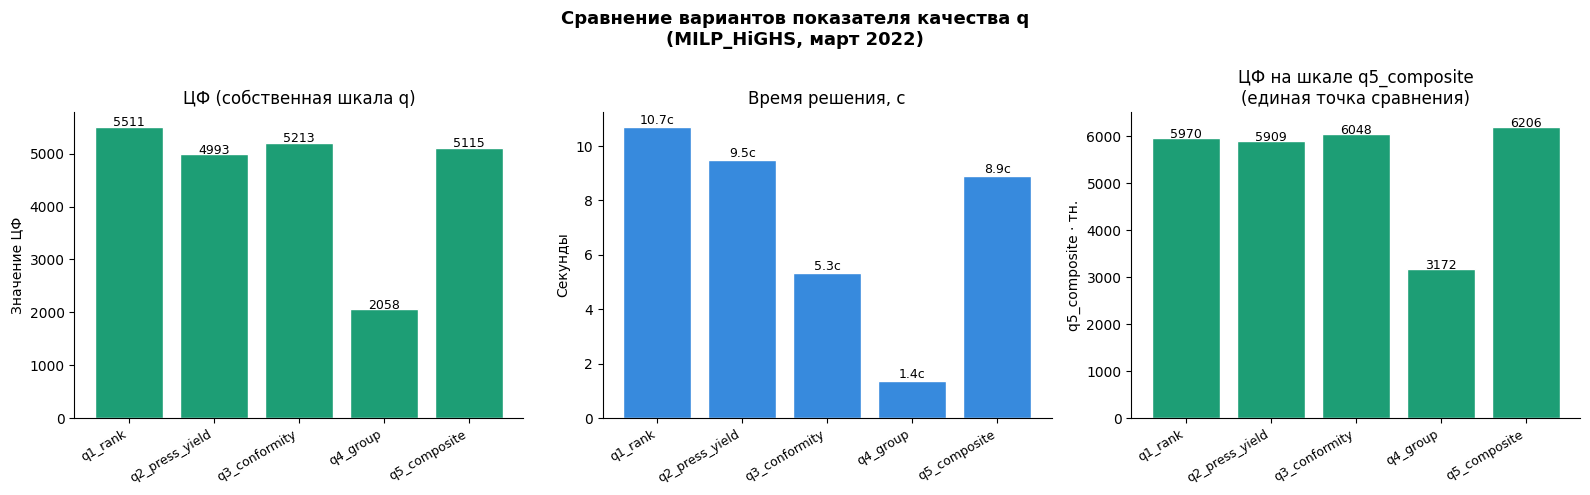

График сохранён: q_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Готово.


In [ ]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  ЯЧЕЙКА — Варианты показателя качества q                       ║
# ║  Запустите после 00_data_prep.py                               ║
# ╚══════════════════════════════════════════════════════════════════╝
#
# Пять вариантов q_{m,r} — показателя качества рецепта:
#
#  q1_rank        — нормированный ранг шихты внутри марки (текущая заглушка)
#  q2_press_yield — выход годного при прессовке (из Прессовка.xls)
#  q3_conformity  — соответствие факта норме (1 − нормированное отклонение)
#  q4_group       — инверсия брака группы изделий (из Проценты.xls)
#  q5_composite   — взвешенная комбинация q2 + q3 + q4
#
# Для шихт без исторических данных используется q1_rank как fallback.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time
from scipy.optimize import milp, LinearConstraint, Bounds
from scipy.sparse import lil_matrix, csr_matrix

DATA_DIR = "/content"
MONTH    = "март 2022"
LD_MONTH = "март 2022"

# ─────────────────────────────────────────────────────────────────
# 1. ЗАГРУЗКА ДОПОЛНИТЕЛЬНЫХ ТАБЛИЦ
# ─────────────────────────────────────────────────────────────────
print("[1] Загрузка данных для вычисления q...")

sheets    = ["март 2022", "апрель 2022", "май 2022"]
ld_sheets = ["март 2022", "аперль 2022", "май 2022"]

df_sh  = pd.concat([pd.read_excel(f"{DATA_DIR}/Шихта.xls",
                    sheet_name=s, engine="xlrd") for s in sheets])
df_ld  = pd.concat([pd.read_excel(f"{DATA_DIR}/Линии_дозирования.xls",
                    sheet_name=s, engine="xlrd") for s in ld_sheets])
df_pr  = pd.concat([pd.read_excel(f"{DATA_DIR}/Прессовка.xls",
                    sheet_name=s, engine="xlrd") for s in sheets])
df_pct = pd.read_excel(f"{DATA_DIR}/Проценты.xls",
                       sheet_name="март 2022", engine="xlrd")
df_z   = pd.read_excel(f"{DATA_DIR}/Заказы.xls",
                       sheet_name=MONTH, engine="xlrd")

print("  Загружено.")


# ─────────────────────────────────────────────────────────────────
# 2. БАЗОВЫЙ ПОКАЗАТЕЛЬ: q1_rank (нормированный ранг)
# ─────────────────────────────────────────────────────────────────
q1_rank = {}
for mc, sh in recipes.items():
    sn_s = sorted(sh.keys()); n = len(sn_s)
    for k, sn in enumerate(sn_s):
        q1_rank[(mc, sn)] = (k + 1) / n


# ─────────────────────────────────────────────────────────────────
# 3. q2_press_yield — выход годного при прессовке
# ─────────────────────────────────────────────────────────────────
# Прессовка.xls → Годное/(Годное+Брак) по (Распоряжение, № шихты)
# Мост Распоряжение→Марка массы из Линий дозирования

bridge   = df_ld[["Марка массы, код", "Распоряжение, код"]].drop_duplicates()
df_pr2   = df_pr.merge(bridge, on="Распоряжение, код", how="left")
pr_grp   = df_pr2.groupby(["Марка массы, код", "№ шихты"])[
               ["Годное, тн.", "Брак, тн."]].sum()
pr_grp["press_yield"] = (pr_grp["Годное, тн."] /
    (pr_grp["Годное, тн."] + pr_grp["Брак, тн."]).replace(0, np.nan))

# Нормируем внутри каждой марки массы → [0, 1]
q2_raw = pr_grp["press_yield"].dropna()
q2_press_yield: dict[tuple[int, int], float] = {}

for mc in q2_raw.index.get_level_values(0).unique():
    sub = q2_raw.xs(mc, level=0)
    mn, mx = sub.min(), sub.max()
    for sn, val in sub.items():
        key = (int(mc), int(sn))
        q2_press_yield[key] = (val - mn) / (mx - mn) if mx > mn else 1.0

# Fallback для шихт без данных прессовки
for key in q1_rank:
    if key not in q2_press_yield:
        q2_press_yield[key] = q1_rank[key]

print(f"  q2_press_yield: данных по {len(pr_grp.dropna())} шихтам, "
      f"fallback для {sum(1 for k in q1_rank if k not in pr_grp.index)} шихт")


# ─────────────────────────────────────────────────────────────────
# 4. q3_conformity — соответствие фактического расхода норме рецепта
# ─────────────────────────────────────────────────────────────────
# Для каждой шихты: насколько фактические доли компонентов
# (из Линий дозирования) отличаются от рецептурных норм (из Шихты).
# conformity = 1 − нормированное_отклонение (меньше отклонение → лучше)

ld_total = (df_ld.groupby(["Марка массы, код", "Номер шихты"])["Годное, тн."]
            .sum().rename("total"))
ld_comp  = (df_ld.groupby(["Марка массы, код", "Номер шихты", "Компонент, код"])
            ["Годное, тн."].sum().rename("fact_ton").reset_index())
ld_comp  = ld_comp.merge(ld_total.reset_index(),
                         on=["Марка массы, код", "Номер шихты"])
ld_comp["fact_pct"] = ld_comp["fact_ton"] / ld_comp["total"] * 100

sh_norm = (df_sh.groupby(["Марка массы, код", "Номер шихты", "Компонент, код"])
           ["Норма, %"].mean().reset_index())
merged   = ld_comp.merge(sh_norm,
           on=["Марка массы, код", "Номер шихты", "Компонент, код"],
           how="inner")
merged["deviation"] = (merged["fact_pct"] - merged["Норма, %"]).abs()
dev_by_sn = merged.groupby(["Марка массы, код", "Номер шихты"])["deviation"].mean()

q3_conformity: dict[tuple[int, int], float] = {}
for mc in dev_by_sn.index.get_level_values(0).unique():
    sub = dev_by_sn.xs(mc, level=0)
    mn, mx = sub.min(), sub.max()
    for sn, dev in sub.items():
        # Инвертируем: маленькое отклонение → высокое качество
        norm = (dev - mn) / (mx - mn) if mx > mn else 0.0
        q3_conformity[(int(mc), int(sn))] = 1.0 - norm

for key in q1_rank:
    if key not in q3_conformity:
        q3_conformity[key] = q1_rank[key]

print(f"  q3_conformity:  данных по {len(dev_by_sn)} шихтам, "
      f"fallback для {sum(1 for k in q1_rank if k not in dev_by_sn.index)} шихт")


# ─────────────────────────────────────────────────────────────────
# 5. q4_group — инверсия брака группы изделий
# ─────────────────────────────────────────────────────────────────
# Проценты.xls: % брака прессовки + % брака обжига по группе сырца.
# Привязка: группа сырца → марка массы через Заказы.xls

# Суммарный % брака по группе сырца
df_pct["total_defect_%"] = (df_pct["%т брака обжига"] +
                            df_pct["% брака перссовки"])
pct_map = df_pct.set_index("Группа сырца, код")["total_defect_%"].to_dict()

# Марка массы → группа сырца через Заказы
grade_to_group = (df_z.groupby("Марка массы, код")["Группа сырца, код"]
                  .first().to_dict())

# Инвертируем: меньше брак → выше q; нормируем в [0,1]
defect_vals = list(pct_map.values())
d_min, d_max = min(defect_vals), max(defect_vals)

q4_group: dict[tuple[int, int], float] = {}
for mc, sh in recipes.items():
    grp = grade_to_group.get(mc)
    defect = pct_map.get(grp, None)
    for sn in sh:
        if defect is not None:
            norm = (defect - d_min) / (d_max - d_min) if d_max > d_min else 0.0
            q4_group[(mc, sn)] = 1.0 - norm
        else:
            q4_group[(mc, sn)] = q1_rank[(mc, sn)]

print(f"  q4_group:       покрыто {sum(1 for k,v in q4_group.items() if v != q1_rank.get(k))} шихт через группы изделий")


# ─────────────────────────────────────────────────────────────────
# 6. q5_composite — взвешенная комбинация
# ─────────────────────────────────────────────────────────────────
# q5 = 0.4·q2 + 0.4·q3 + 0.2·q4
# Веса можно менять. Логика: прессовка и соответствие норме равнозначны,
# групповой брак — вспомогательный показатель.

W2, W3, W4 = 0.4, 0.4, 0.2

q5_composite: dict[tuple[int, int], float] = {
    key: W2 * q2_press_yield[key] + W3 * q3_conformity[key] + W4 * q4_group[key]
    for key in q1_rank
}

print(f"  q5_composite:   W2={W2}, W3={W3}, W4={W4}")


# ─────────────────────────────────────────────────────────────────
# 7. СВОДНАЯ ТАБЛИЦА ЗНАЧЕНИЙ q ПО ШИХТАМ
# ─────────────────────────────────────────────────────────────────
all_keys = sorted(q1_rank.keys())
df_q = pd.DataFrame({
    "Марка_массы_код": [k[0] for k in all_keys],
    "Шихта_номер":     [k[1] for k in all_keys],
    "q1_rank":         [round(q1_rank[k], 4) for k in all_keys],
    "q2_press_yield":  [round(q2_press_yield[k], 4) for k in all_keys],
    "q3_conformity":   [round(q3_conformity[k], 4) for k in all_keys],
    "q4_group":        [round(q4_group[k], 4) for k in all_keys],
    "q5_composite":    [round(q5_composite[k], 4) for k in all_keys],
})
print(f"\n  Всего шихт: {len(df_q)}")
print(df_q.describe().round(3).to_string())


# ─────────────────────────────────────────────────────────────────
# 8. ЗАПУСК MILP ДЛЯ КАЖДОГО ВАРИАНТА q
# ─────────────────────────────────────────────────────────────────
print("\n[2] Запуск MILP для каждого варианта q...")

Q_VARIANTS = {
    "q1_rank":        q1_rank,
    "q2_press_yield": q2_press_yield,
    "q3_conformity":  q3_conformity,
    "q4_group":       q4_group,
    "q5_composite":   q5_composite,
}

# Строим матрицу ограничений один раз (она не зависит от q)
var_list  = [(o["id"], o["mass_code"], sn)
             for o in orders for sn in recipes[o["mass_code"]]]
var_index = {v: i for i, v in enumerate(var_list)}
nv = len(var_list)

comp_to_row = {c: len(orders) + i for i, c in enumerate(constrained_comps)}
nc = len(orders) + len(constrained_comps)
A  = lil_matrix((nc, nv))
bl = np.full(nc, -np.inf); bh = np.full(nc, np.inf)

for o in orders:
    r = o["id"]; bl[r] = bh[r] = 1.0
    for sn in recipes[o["mass_code"]]:
        key = (o["id"], o["mass_code"], sn)
        if key in var_index: A[r, var_index[key]] = 1.0

for i, (oid, mc, sn) in enumerate(var_list):
    d = orders[oid]["demand"]
    for c, nm in recipes[mc][sn].items():
        if c in comp_to_row: A[comp_to_row[c], i] += (nm / 100) * d

for c in constrained_comps:
    bh[comp_to_row[c]] = supply[c]

A_csr = csr_matrix(A)

milp_results = {}

for q_name, q_dict in Q_VARIANTS.items():
    c_obj = np.array([-q_dict.get((mc, sn), 0.5) * orders[oid]["demand"]
                       for oid, mc, sn in var_list])
    t0 = time.time()
    res = milp(c_obj,
               constraints=LinearConstraint(A_csr, bl, bh),
               integrality=np.ones(nv),
               bounds=Bounds(np.zeros(nv), np.ones(nv)),
               options={"disp": False, "time_limit": 120})
    elapsed = time.time() - t0

    asgn = [None] * len(orders)
    if res.x is not None:
        for i, (oid, mc, sn) in enumerate(var_list):
            if res.x[i] > 0.5: asgn[oid] = sn

    obj_val, viol, used = compute_metrics(asgn)

    # Считаем ЦФ по КАЖДОМУ q для одного и того же назначения
    # (чтобы сравнивать яблоки с яблоками)
    cf_by_q = {}
    for other_name, other_q in Q_VARIANTS.items():
        cf_by_q[other_name] = round(sum(
            other_q.get((orders[i]["mass_code"], sn), 0) * orders[i]["demand"]
            for i, sn in enumerate(asgn) if sn is not None
        ), 3)

    milp_results[q_name] = {
        "asgn":    asgn,
        "obj_opt": round(-res.fun if res.x is not None else 0, 3),
        "obj_val": round(obj_val, 3),
        "viol":    round(viol, 4),
        "time":    round(elapsed, 2),
        "status":  "Optimal" if res.status == 0 else res.message[:20],
        "cf_by_q": cf_by_q,
    }
    print(f"  {q_name:<18}  ЦФ={obj_val:>9.2f}  t={elapsed:>6.2f}с  "
          f"нарушение={viol:.4f}  {milp_results[q_name]['status']}")


# ─────────────────────────────────────────────────────────────────
# 9. СРАВНИТЕЛЬНАЯ ТАБЛИЦА РЕЗУЛЬТАТОВ
# ─────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("СРАВНЕНИЕ НАЗНАЧЕНИЙ ПО ВАРИАНТАМ q")
print("═" * 70)

rows = []
for q_name, r in milp_results.items():
    rows.append({
        "Вариант q":       q_name,
        "ЦФ (своя шкала)": r["obj_val"],
        "Допустимо":       "Да" if r["viol"] < 1e-3 else "Нет",
        "Нарушение, тн.":  r["viol"],
        "Время, с":        r["time"],
        "Статус":          r["status"],
    })

df_res = pd.DataFrame(rows)
print(df_res.to_string(index=False))

# Кросс-таблица: ЦФ назначения варианта q_строка, измеренная по шкале q_столбца
print("\n  Кросс-таблица ЦФ (строка = чем оптимизировали, столбец = чем измеряем):")
cross_rows = []
for q_name, r in milp_results.items():
    row = {"Оптимизировано по": q_name}
    row.update(r["cf_by_q"])
    cross_rows.append(row)
df_cross = pd.DataFrame(cross_rows).set_index("Оптимизировано по")
print(df_cross.round(1).to_string())


# ─────────────────────────────────────────────────────────────────
# 10. ГРАФИКИ
# ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Сравнение вариантов показателя качества q\n(MILP_HiGHS, март 2022)",
             fontsize=13, fontweight="bold")

q_names  = list(milp_results.keys())
colors   = ["#1D9E75" if milp_results[q]["viol"] < 1e-3 else "#D85A30"
            for q in q_names]

# График 1: ЦФ (каждый по своей шкале)
ax = axes[0]
vals = [milp_results[q]["obj_val"] for q in q_names]
bars = ax.bar(q_names, vals, color=colors, edgecolor="white")
for bar, v in zip(bars, vals):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 10,
            f"{v:.0f}", ha="center", fontsize=9)
ax.set_title("ЦФ (собственная шкала q)")
ax.set_ylabel("Значение ЦФ")
ax.set_xticklabels(q_names, rotation=30, ha="right", fontsize=9)
ax.spines[["top","right"]].set_visible(False)

# График 2: время решения
ax = axes[1]
times = [milp_results[q]["time"] for q in q_names]
ax.bar(q_names, times, color="#378ADD", edgecolor="white")
for i, v in enumerate(times):
    ax.text(i, v + 0.1, f"{v:.1f}с", ha="center", fontsize=9)
ax.set_title("Время решения, с")
ax.set_ylabel("Секунды")
ax.set_xticklabels(q_names, rotation=30, ha="right", fontsize=9)
ax.spines[["top","right"]].set_visible(False)

# График 3: кросс-оценка — насколько q1_rank соответствует другим шкалам
# Показываем: для каждого варианта q, какой ЦФ по шкале q5_composite
ax = axes[2]
cf_on_composite = [milp_results[q]["cf_by_q"]["q5_composite"] for q in q_names]
bars = ax.bar(q_names, cf_on_composite, color=colors, edgecolor="white")
for bar, v in zip(bars, cf_on_composite):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
            f"{v:.0f}", ha="center", fontsize=9)
ax.set_title("ЦФ на шкале q5_composite\n(единая точка сравнения)")
ax.set_ylabel("q5_composite · тн.")
ax.set_xticklabels(q_names, rotation=30, ha="right", fontsize=9)
ax.spines[["top","right"]].set_visible(False)

plt.tight_layout()
plt.savefig("/content/q_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("График сохранён: q_comparison.png")


# ─────────────────────────────────────────────────────────────────
# 11. ЭКСПОРТ
# ─────────────────────────────────────────────────────────────────
df_q.to_csv("/content/q_values_all_shikhtas.csv", index=False, encoding="utf-8-sig")
df_res.to_csv("/content/q_milp_summary.csv", index=False, encoding="utf-8-sig")
df_cross.to_csv("/content/q_cross_table.csv", encoding="utf-8-sig")

from google.colab import files
files.download("/content/q_comparison.png")
files.download("/content/q_values_all_shikhtas.csv")
files.download("/content/q_milp_summary.csv")
files.download("/content/q_cross_table.csv")
print("Готово.")

Строим матрицу ограничений...
  Переменных: 33847, ограничений: 268, nnz: 258813

══════════════════════════════════════════════════════════════════════
ЗАПУСК: 5 варианта q × 8 методов = 40 экспериментов
══════════════════════════════════════════════════════════════════════

── q1_rank ──────────────────────────────
  MILP_HiGHS            ЦФ=  5511.37  нарушение=   0.000  t=  11.05с  OK
  LP_Relax              ЦФ=  5497.01  нарушение=   2.578  t=   1.09с  НАРУШЕНИЕ
  ILP_CBC               ЦФ=  5505.02  нарушение=   0.000  t= 121.78с  OK
  Greedy_Quality        ЦФ=  5418.23  нарушение=   9.753  t=   0.02с  НАРУШЕНИЕ
  Greedy_Demand         ЦФ=  5712.58  нарушение= 145.182  t=   0.03с  НАРУШЕНИЕ
  SimAnneal             ЦФ=  5159.63  нарушение=   0.000  t=   4.00с  OK
  Random_Restart        ЦФ=  3686.67  нарушение=3317.018  t=   1.34с  НАРУШЕНИЕ
  Decomp_Hungarian      ЦФ=  2899.12  нарушение=3788.072  t=   0.01с  НАРУШЕНИЕ

── q2_press_yield ──────────────────────────────
  MILP_HiGHS

/tmp/ipykernel_2724/1184886565.py:367: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(q_labels, rotation=35, ha="right", fontsize=8)


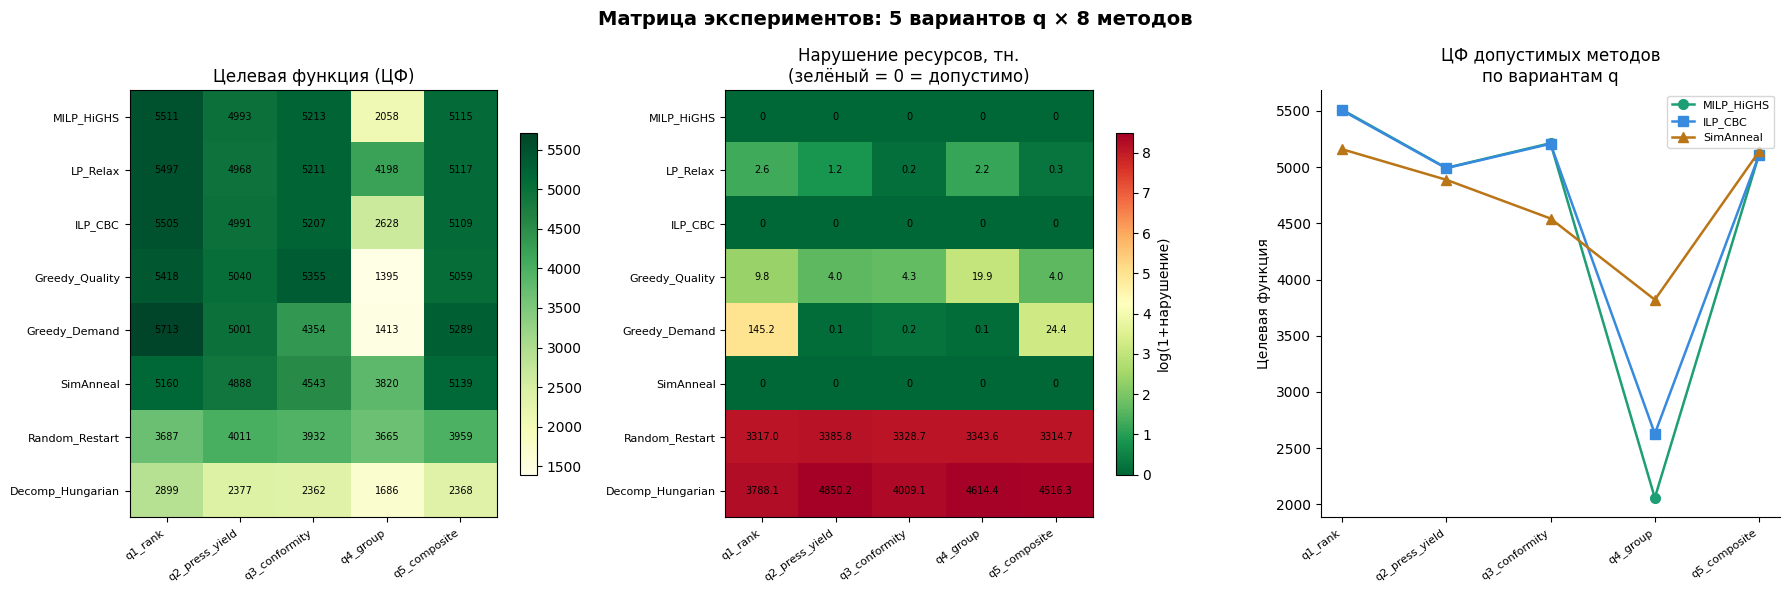

График сохранён: full_experiment.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# ╔══════════════════════════════════════════════════════════════════╗
# ║  ПОЛНЫЙ ЭКСПЕРИМЕНТ: 5 вариантов q × 8 методов = 40 запусков  ║
# ╚══════════════════════════════════════════════════════════════════╝
import time, random, math
import numpy as np
import pandas as pd
import pulp
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from scipy.optimize import milp, LinearConstraint, Bounds, linear_sum_assignment
from scipy.sparse import lil_matrix, csr_matrix
from collections import defaultdict
from google.colab import files

random.seed(42)
np.random.seed(42)

# ── Варианты q (из 10_quality_variants.py) ────────────────────────
Q_VARIANTS = {
    "q1_rank":        q1_rank,
    "q2_press_yield": q2_press_yield,
    "q3_conformity":  q3_conformity,
    "q4_group":       q4_group,
    "q5_composite":   q5_composite,
}

# ─────────────────────────────────────────────────────────────────
# МАТРИЦА ОГРАНИЧЕНИЙ (одна для всех методов и всех q)
# ─────────────────────────────────────────────────────────────────
print("Строим матрицу ограничений...")

var_list  = [(o["id"], o["mass_code"], sn)
             for o in orders for sn in recipes[o["mass_code"]]]
var_index = {v: i for i, v in enumerate(var_list)}
nv = len(var_list)

comp_to_row = {c: len(orders) + i for i, c in enumerate(constrained_comps)}
nc = len(orders) + len(constrained_comps)
A  = lil_matrix((nc, nv))
bl = np.full(nc, -np.inf); bh = np.full(nc, np.inf)

for o in orders:
    r = o["id"]; bl[r] = bh[r] = 1.0
    for sn in recipes[o["mass_code"]]:
        key = (o["id"], o["mass_code"], sn)
        if key in var_index: A[r, var_index[key]] = 1.0

for i, (oid, mc, sn) in enumerate(var_list):
    d = orders[oid]["demand"]
    for c, nm in recipes[mc][sn].items():
        if c in comp_to_row: A[comp_to_row[c], i] += (nm / 100) * d

for c in constrained_comps:
    bh[comp_to_row[c]] = supply[c]

A_csr = csr_matrix(A)
print(f"  Переменных: {nv}, ограничений: {nc}, nnz: {A_csr.nnz}")


# ─────────────────────────────────────────────────────────────────
# РЕАЛИЗАЦИИ МЕТОДОВ (каждый принимает q_dict как параметр)
# ─────────────────────────────────────────────────────────────────

def run_milp_highs(q_dict):
    c_obj = np.array([-q_dict.get((mc, sn), 0.5) * orders[oid]["demand"]
                       for oid, mc, sn in var_list])
    t0 = time.time()
    res = milp(c_obj,
               constraints=LinearConstraint(A_csr, bl, bh),
               integrality=np.ones(nv),
               bounds=Bounds(np.zeros(nv), np.ones(nv)),
               options={"disp": False, "time_limit": 120})
    elapsed = time.time() - t0
    asgn = [None] * len(orders)
    if res.x is not None:
        for i, (oid, mc, sn) in enumerate(var_list):
            if res.x[i] > 0.5: asgn[oid] = sn
    return asgn, elapsed


def run_lp_relax(q_dict):
    c_obj = np.array([-q_dict.get((mc, sn), 0.5) * orders[oid]["demand"]
                       for oid, mc, sn in var_list])
    t0 = time.time()
    res = milp(c_obj,
               constraints=LinearConstraint(A_csr, bl, bh),
               integrality=np.zeros(nv),
               bounds=Bounds(np.zeros(nv), np.ones(nv)),
               options={"disp": False})
    elapsed = time.time() - t0
    asgn = [None] * len(orders)
    if res.x is not None:
        xv = res.x
        for o in orders:
            mc = o["mass_code"]
            best_val, best_sn = -1.0, None
            for sn in recipes[mc]:
                key = (o["id"], mc, sn)
                if key in var_index:
                    v = xv[var_index[key]]
                    if v > best_val: best_val, best_sn = v, sn
            asgn[o["id"]] = best_sn
    return asgn, elapsed


def run_ilp_cbc(q_dict):
    vrs = {(oid, mc, sn): pulp.LpVariable(f"x_{oid}_{mc}_{sn}", cat="Binary")
           for oid, mc, sn in var_list}
    prob = pulp.LpProblem("cbc", pulp.LpMaximize)
    prob += pulp.lpSum(q_dict.get((mc, sn), 0.5) * orders[oid]["demand"] * vrs[(oid, mc, sn)]
                       for oid, mc, sn in var_list)
    for o in orders:
        mc = o["mass_code"]
        prob += (pulp.lpSum(vrs[(o["id"], mc, sn)] for sn in recipes[mc]) == 1)
    for c in constrained_comps:
        prob += (pulp.lpSum(
            (recipes[mc][sn].get(c, 0) / 100) * orders[oid]["demand"] * vrs[(oid, mc, sn)]
            for oid, mc, sn in var_list if c in recipes[mc][sn]
        ) <= supply[c])
    t0 = time.time()
    prob.solve(pulp.PULP_CBC_CMD(msg=0, timeLimit=120))
    elapsed = time.time() - t0
    asgn = [None] * len(orders)
    for oid, mc, sn in var_list:
        v = pulp.value(vrs[(oid, mc, sn)])
        if v is not None and v > 0.5: asgn[oid] = sn
    return asgn, elapsed


def _greedy_core(order_indices, q_dict):
    asgn = [None] * len(orders)
    comp_used = {c: 0.0 for c in supply}
    for oi in order_indices:
        o = orders[oi]; mc = o["mass_code"]; d = o["demand"]
        sorted_sn = sorted(recipe_lists[mc], key=lambda sn: -q_dict.get((mc, sn), 0))
        chosen = None
        for sn in sorted_sn:
            if all(comp_used.get(c, 0) + (nm / 100) * d <= supply[c]
                   for c, nm in recipes[mc][sn].items() if c in supply):
                chosen = sn; break
        if chosen is None: chosen = sorted_sn[0]
        asgn[oi] = chosen
        for c, nm in recipes[mc][chosen].items():
            if c in supply: comp_used[c] = comp_used.get(c, 0) + (nm / 100) * d
    return asgn


def run_greedy_quality(q_dict):
    idx = sorted(range(len(orders)),
                 key=lambda i: -max(q_dict.get((orders[i]["mass_code"], sn), 0)
                                    for sn in recipe_lists[orders[i]["mass_code"]]))
    t0 = time.time()
    asgn = _greedy_core(idx, q_dict)
    return asgn, time.time() - t0


def run_greedy_demand(q_dict):
    idx = sorted(range(len(orders)), key=lambda i: -orders[i]["demand"])
    t0 = time.time()
    asgn = _greedy_core(idx, q_dict)
    return asgn, time.time() - t0


def run_sim_anneal(q_dict, n_iters=50_000, T_start=500.0, T_end=0.01, penalty=5000.0):
    alpha = (T_end / T_start) ** (1.0 / n_iters)

    def energy(asgn, used):
        obj  = sum(q_dict.get((orders[i]["mass_code"], sn), 0) * orders[i]["demand"]
                   for i, sn in enumerate(asgn))
        viol = sum(max(0.0, used[c] - supply[c]) for c in supply)
        return -obj + penalty * viol

    def delta_used(i, old_sn, new_sn):
        mc = orders[i]["mass_code"]; d = orders[i]["demand"]
        delta = {}
        for c in set(list(recipes[mc][old_sn]) + list(recipes[mc][new_sn])):
            if c in supply:
                dv = (recipes[mc][new_sn].get(c, 0) -
                      recipes[mc][old_sn].get(c, 0)) / 100 * d
                if dv: delta[c] = dv
        return delta

    cur_asgn = [max(recipe_lists[o["mass_code"]],
                    key=lambda sn: q_dict.get((o["mass_code"], sn), 0))
                for o in orders]
    _, _, cur_used = compute_metrics(cur_asgn)
    cur_e = energy(cur_asgn, cur_used)
    best_asgn = list(cur_asgn); best_e = cur_e; best_used = dict(cur_used)
    T = T_start

    t0 = time.time()
    for _ in range(n_iters):
        idx    = random.randrange(len(orders))
        mc     = orders[idx]["mass_code"]
        old_sn = cur_asgn[idx]
        new_sn = random.choice(recipe_lists[mc])
        if new_sn == old_sn: T *= alpha; continue
        delta  = delta_used(idx, old_sn, new_sn)
        new_used = dict(cur_used)
        for c, dv in delta.items(): new_used[c] += dv
        new_asgn = list(cur_asgn); new_asgn[idx] = new_sn
        new_e = energy(new_asgn, new_used)
        if new_e < cur_e or random.random() < math.exp(-(new_e - cur_e) / T):
            cur_asgn, cur_used, cur_e = new_asgn, new_used, new_e
            if cur_e < best_e:
                best_asgn, best_e, best_used = list(cur_asgn), cur_e, dict(cur_used)
        T *= alpha
    return best_asgn, time.time() - t0


def run_random_restart(q_dict, restarts=2000):
    best_asgn = None; best_obj = -np.inf; best_viol = np.inf
    t0 = time.time()
    for _ in range(restarts):
        asgn = [random.choice(recipe_lists[o["mass_code"]]) for o in orders]
        obj, viol, _ = compute_metrics(asgn)
        if viol < 1e-3 and obj > best_obj:
            best_obj = obj; best_asgn = list(asgn); best_viol = viol
        elif best_asgn is None or (best_viol > 1e-3 and viol < best_viol):
            best_asgn = list(asgn); best_viol = viol
    return best_asgn, time.time() - t0


def run_hungarian(q_dict):
    asgn = [None] * len(orders)
    grade_orders = defaultdict(list)
    for o in orders: grade_orders[o["mass_code"]].append(o["id"])
    t0 = time.time()
    for mc, oids in grade_orders.items():
        sn_list = recipe_lists[mc]; nr = len(sn_list); no = len(oids)
        sn_exp  = (sn_list * math.ceil(no / nr))[:no]
        cost    = np.array([[-q_dict.get((mc, sn), 0) * orders[oid]["demand"]
                              for sn in sn_exp] for oid in oids])
        row_ind, col_ind = linear_sum_assignment(cost)
        for oi, ri in zip(row_ind, col_ind):
            asgn[oids[oi]] = sn_exp[ri]
    return asgn, time.time() - t0


METHODS = {
    "MILP_HiGHS":      run_milp_highs,
    "LP_Relax":        run_lp_relax,
    "ILP_CBC":         run_ilp_cbc,
    "Greedy_Quality":  run_greedy_quality,
    "Greedy_Demand":   run_greedy_demand,
    "SimAnneal":       run_sim_anneal,
    "Random_Restart":  run_random_restart,
    "Decomp_Hungarian":run_hungarian,
}

# ─────────────────────────────────────────────────────────────────
# ГЛАВНЫЙ ЦИКЛ: 5 q × 8 методов
# ─────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print(f"ЗАПУСК: {len(Q_VARIANTS)} варианта q × {len(METHODS)} методов = "
      f"{len(Q_VARIANTS)*len(METHODS)} экспериментов")
print("═" * 70)

all_results = []   # список словарей — одна строка = один эксперимент

for q_name, q_dict in Q_VARIANTS.items():
    print(f"\n── {q_name} ──────────────────────────────")
    for m_name, m_func in METHODS.items():
        try:
            asgn, elapsed = m_func(q_dict)
            obj, viol, _  = compute_metrics(asgn)
        except Exception as e:
            print(f"  {m_name:<20} ОШИБКА: {e}")
            obj, viol, elapsed = 0.0, 999.0, 0.0
            asgn = [None] * len(orders)

        feasible = viol < 1e-3
        print(f"  {m_name:<20}  ЦФ={obj:>9.2f}  "
              f"нарушение={viol:>8.3f}  t={elapsed:>7.2f}с  "
              f"{'OK' if feasible else 'НАРУШЕНИЕ'}")

        all_results.append({
            "q_variant":      q_name,
            "Метод":          m_name,
            "ЦФ":             round(obj, 3),
            "Время, с":       round(elapsed, 3),
            "Нарушение, тн.": round(viol, 4),
            "Допустимо":      feasible,
        })

df_all = pd.DataFrame(all_results)

# ─────────────────────────────────────────────────────────────────
# СВОДНЫЕ ТАБЛИЦЫ
# ─────────────────────────────────────────────────────────────────
print("\n" + "═" * 70)
print("СВОДНАЯ ТАБЛИЦА ЦФ (строки = методы, столбцы = варианты q)")
print("═" * 70)
pivot_cf = df_all.pivot(index="Метод", columns="q_variant", values="ЦФ")
pivot_cf = pivot_cf.reindex(list(METHODS.keys()))
print(pivot_cf.round(1).to_string())

print("\nСВОДНАЯ ТАБЛИЦА НАРУШЕНИЙ (0 = допустимо)")
pivot_viol = df_all.pivot(index="Метод", columns="q_variant", values="Нарушение, тн.")
pivot_viol = pivot_viol.reindex(list(METHODS.keys()))
print(pivot_viol.round(3).to_string())

print("\nСВОДНАЯ ТАБЛИЦА ВРЕМЕНИ, с")
pivot_time = df_all.pivot(index="Метод", columns="q_variant", values="Время, с")
pivot_time = pivot_time.reindex(list(METHODS.keys()))
print(pivot_time.round(2).to_string())

# ─────────────────────────────────────────────────────────────────
# ГРАФИКИ
# ─────────────────────────────────────────────────────────────────
q_labels = list(Q_VARIANTS.keys())
m_labels  = list(METHODS.keys())
n_q, n_m  = len(q_labels), len(m_labels)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle("Матрица экспериментов: 5 вариантов q × 8 методов",
             fontsize=14, fontweight="bold")

# ── Тепловая карта ЦФ ─────────────────────────────────────────
ax = axes[0]
data_cf = pivot_cf.values.astype(float)
im = ax.imshow(data_cf, cmap="YlGn", aspect="auto")
plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_xticks(range(n_q)); ax.set_xticklabels(q_labels, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(n_m)); ax.set_yticklabels(m_labels, fontsize=8)
ax.set_title("Целевая функция (ЦФ)")
for i in range(n_m):
    for j in range(n_q):
        v = data_cf[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.0f}", ha="center", va="center",
                    fontsize=7, color="black")

# ── Тепловая карта нарушений ──────────────────────────────────
ax = axes[1]
data_viol = pivot_viol.values.astype(float)
data_viol_log = np.log1p(data_viol)
im2 = ax.imshow(data_viol_log, cmap="RdYlGn_r", aspect="auto")
plt.colorbar(im2, ax=ax, shrink=0.8, label="log(1+нарушение)")
ax.set_xticks(range(n_q)); ax.set_xticklabels(q_labels, rotation=35, ha="right", fontsize=8)
ax.set_yticks(range(n_m)); ax.set_yticklabels(m_labels, fontsize=8)
ax.set_title("Нарушение ресурсов, тн.\n(зелёный = 0 = допустимо)")
for i in range(n_m):
    for j in range(n_q):
        v = data_viol[i, j]
        if not np.isnan(v):
            label = "0" if v < 0.001 else f"{v:.1f}"
            ax.text(j, i, label, ha="center", va="center",
                    fontsize=7, color="black")

# ── Линейный график: ЦФ лучших допустимых методов по вариантам q
ax = axes[2]
feasible_methods = ["MILP_HiGHS", "ILP_CBC", "SimAnneal"]
line_styles = ["-o", "-s", "-^"]
colors_line = ["#1D9E75", "#378ADD", "#BA7517"]
for m_name, ls, col in zip(feasible_methods, line_styles, colors_line):
    vals = []
    for q_name in q_labels:
        row = df_all[(df_all["Метод"] == m_name) & (df_all["q_variant"] == q_name)]
        if not row.empty and row.iloc[0]["Допустимо"]:
            vals.append(row.iloc[0]["ЦФ"])
        else:
            vals.append(np.nan)
    ax.plot(q_labels, vals, ls, label=m_name, color=col, linewidth=1.8, markersize=7)

ax.set_xticklabels(q_labels, rotation=35, ha="right", fontsize=8)
ax.set_ylabel("Целевая функция")
ax.set_title("ЦФ допустимых методов\nпо вариантам q")
ax.legend(fontsize=8)
ax.spines[["top","right"]].set_visible(False)

plt.tight_layout()
plt.savefig("/content/full_experiment.png", dpi=150, bbox_inches="tight")
plt.show()
print("График сохранён: full_experiment.png")

# ─────────────────────────────────────────────────────────────────
# ЭКСПОРТ
# ─────────────────────────────────────────────────────────────────
df_all.to_csv("/content/full_experiment_raw.csv", index=False, encoding="utf-8-sig")
pivot_cf.to_csv("/content/pivot_cf.csv", encoding="utf-8-sig")
pivot_viol.to_csv("/content/pivot_violation.csv", encoding="utf-8-sig")
pivot_time.to_csv("/content/pivot_time.csv", encoding="utf-8-sig")

files.download("/content/full_experiment.png")
files.download("/content/full_experiment_raw.csv")
files.download("/content/pivot_cf.csv")
files.download("/content/pivot_violation.csv")
